In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
import indices as ix

rng = np.random.default_rng(1)
x = stats.fisk.rvs(c=4, loc=-900, scale=150, size=50000, random_state=rng)
xi, a, k = ix.loglogistic_fit(x)
beta = -1 / k
print(f"alpha {beta * a:.0f}, beta {beta:.2f}, origin {xi - beta * a:.0f}   (true 150, 4, -900)")

t = pd.date_range("1981-01-01", "2023-12-01", freq="MS")
samples = {
    "log-logistic": stats.fisk.rvs(c=4, loc=-900, scale=150, size=t.size, random_state=rng),
    "symmetric": rng.normal(-900, 150, t.size),
    "negative skew": -stats.gamma.rvs(3, scale=60, size=t.size, random_state=rng),
}
for name, x in samples.items():
    z = ix.standardise(xr.DataArray(x, dims="time", coords={"time": t}), "loglogistic")
    print(f"{name:14s} mean {float(z.mean()):+.2f}  sd {float(z.std()):.2f}  missing {int(z.isnull().sum())}")

alpha 152, beta 4.06, origin -902   (true 150, 4, -900)
log-logistic   mean +0.01  sd 0.98  missing 0
symmetric      mean +0.00  sd 0.98  missing 0
negative skew  mean -0.01  sd 0.98  missing 0


In [2]:
proc = "../data/processed"
ds = xr.open_dataset(f"{proc}/marathwada_monthly_025.nc")
pe = xr.open_dataset(f"{proc}/marathwada_pet_025.nc")
d_th = ds["pr"] - pe["pet_th"]
d_hg = ds["pr"] - pe["pet_hg"]

scales = [1, 3, 6, 12, 24]

def by_scale(f, x):
    return xr.concat([f(x, k) for k in scales], dim=xr.DataArray(scales, dims="scale", name="scale"))

idx = xr.Dataset({"spi": by_scale(ix.spi, ds["pr"]),
                  "spei_th": by_scale(ix.spei, d_th),
                  "spei_hg": by_scale(ix.spei, d_hg)})

w = np.cos(np.deg2rad(ds.lat))
reg_in = xr.Dataset({"pr": ds["pr"], "pet_th": pe["pet_th"], "pet_hg": pe["pet_hg"]}).weighted(w).mean(("lat", "lon"))
reg_in["d_th"] = reg_in["pr"] - reg_in["pet_th"]
reg_in["d_hg"] = reg_in["pr"] - reg_in["pet_hg"]
reg = xr.Dataset({"spi": by_scale(ix.spi, reg_in["pr"]),
                  "spei_th": by_scale(ix.spei, reg_in["d_th"]),
                  "spei_hg": by_scale(ix.spei, reg_in["d_hg"])})
print(idx)

<xarray.Dataset> Size: 11MB
Dimensions:  (lat: 12, lon: 15, time: 516, scale: 5)
Coordinates:
  * lat      (lat) float64 96B 17.75 18.0 18.25 18.5 ... 19.75 20.0 20.25 20.5
  * lon      (lon) float64 120B 74.75 75.0 75.25 75.5 ... 77.5 77.75 78.0 78.25
  * time     (time) datetime64[ns] 4kB 1981-01-01 1981-02-01 ... 2023-12-01
  * scale    (scale) int64 40B 1 3 6 12 24
Data variables:
    spi      (scale, time, lat, lon) float64 4MB nan nan nan nan ... nan nan nan
    spei_th  (scale, time, lat, lon) float64 4MB nan nan nan nan ... nan nan nan
    spei_hg  (scale, time, lat, lon) float64 4MB nan nan nan nan ... nan nan nan


In [3]:
inside = ds["pr"].notnull().any("time")
z = idx.where(inside).isel(time=slice(23, None)).to_array("index")   # from the first month every scale exists
dims = ("time", "lat", "lon")
print(xr.Dataset({
    "mean": z.mean(dims),
    "sd": z.std(dims),
    "share_le_-1": (z <= -1).sum(dims) / z.notnull().sum(dims),
    "missing": (z.isnull() & inside).sum(dims),
}).to_dataframe().round(2))

miss = (idx["spi"].sel(scale=1).isnull() & inside).groupby("time.month").sum(dims) / (int(inside.sum()) * 43)
print("SPI-1 share of cells without a fit, Jan-Dec:", miss.round(2).values)

ann = reg_in[["pr", "pet_th", "pet_hg"]].resample(time="YS").sum()
print("annual r(P, PET):  Thornthwaite", round(float(xr.corr(ann.pr, ann.pet_th)), 2),
      " Hargreaves", round(float(xr.corr(ann.pr, ann.pet_hg)), 2))

rows = []
for k in range(1, 25):
    s, e1, e2 = ix.spi(reg_in["pr"], k), ix.spei(reg_in["d_th"], k), ix.spei(reg_in["d_hg"], k)
    rows.append((k, float(xr.corr(s, e1)), float(xr.corr(s, e2)), float(xr.corr(e1, e2))))
r = pd.DataFrame(rows, columns=["scale", "spi_vs_spei_th", "spi_vs_spei_hg", "spei_th_vs_hg"]).set_index("scale")
print(r.round(2).loc[[1, 3, 6, 12, 18, 24]])

dec12 = reg.sel(scale=12).where(reg.time.dt.month == 12, drop=True).to_dataframe().drop(columns="scale")
dec12.index = dec12.index.year
print(dec12.sort_values("spei_hg").head(8).round(2))

               mean    sd  share_le_-1  missing
scale index                                    
1     spi      0.02  0.93         0.10       82
      spei_th -0.00  1.00         0.17        0
      spei_hg  0.00  1.00         0.17        0
3     spi      0.01  0.99         0.17        0
      spei_th  0.00  1.00         0.16        0
      spei_hg  0.01  0.99         0.17        0
6     spi      0.01  1.00         0.16        0
      spei_th  0.00  0.99         0.17        0
      spei_hg  0.01  0.99         0.17        0
12    spi      0.00  1.01         0.16        0
      spei_th  0.00  0.99         0.16        0
      spei_hg  0.01  0.99         0.17        0
24    spi     -0.00  1.00         0.16        0
      spei_th  0.01  0.98         0.16        0
      spei_hg  0.01  0.98         0.17        0
SPI-1 share of cells without a fit, Jan-Dec: [0.   0.02 0.   0.   0.   0.   0.   0.   0.   0.   0.   0.  ]
annual r(P, PET):  Thornthwaite -0.21  Hargreaves -0.52
       spi_vs_spei_th

In [4]:
idx["spi"].attrs["long_name"] = "SPI, gamma with zero mass, fitted per calendar month 1981-2023"
idx["spei_th"].attrs["long_name"] = "SPEI with Thornthwaite PET, log-logistic (L-moments) per calendar month"
idx["spei_hg"].attrs["long_name"] = "SPEI with Hargreaves PET, log-logistic (L-moments) per calendar month"
idx.to_netcdf(f"{proc}/marathwada_indices_025.nc")

tab = reg.to_dataframe().unstack("scale")
tab.columns = [f"{v}_{k}" for v, k in tab.columns]
tab.round(3).to_csv("../outputs/tables/marathwada_indices_regional.csv")
r.round(3).to_csv("../outputs/tables/spi_spei_correlation_by_scale.csv")

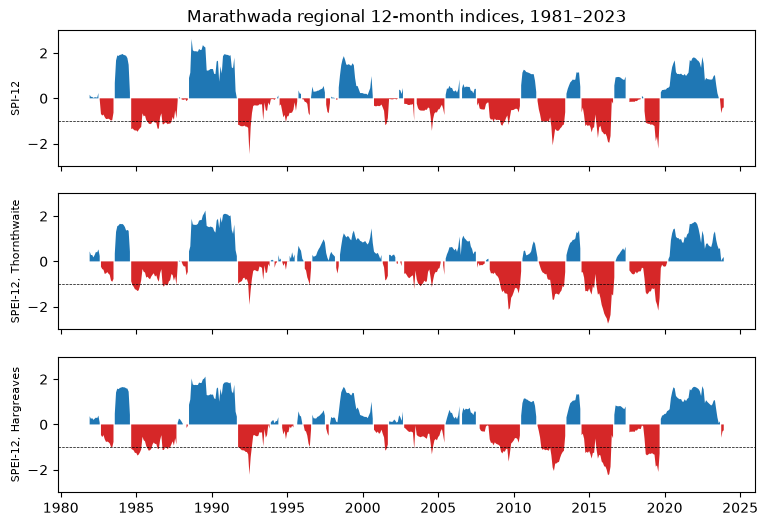

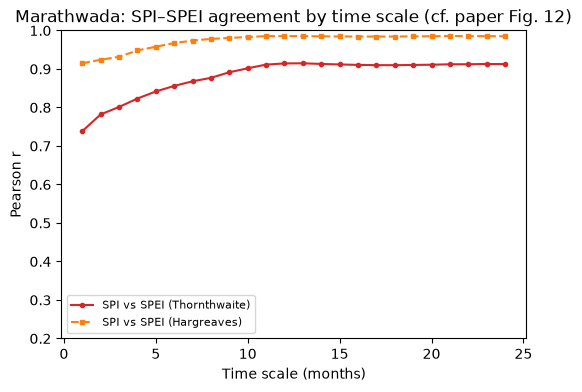

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(9, 6), sharex=True, sharey=True)
for ax, v, title in zip(axes, ["spi", "spei_th", "spei_hg"],
                        ["SPI-12", "SPEI-12, Thornthwaite", "SPEI-12, Hargreaves"]):
    s = reg[v].sel(scale=12).to_series()
    ax.fill_between(s.index, s, 0, where=s >= 0, color="tab:blue", lw=0)
    ax.fill_between(s.index, s, 0, where=s < 0, color="tab:red", lw=0)
    ax.axhline(-1, color="k", lw=0.5, ls="--")
    ax.set_ylabel(title, fontsize=8)
axes[0].set_ylim(-3, 3)
axes[0].set_title("Marathwada regional 12-month indices, 1981–2023")
fig.savefig("../outputs/figures/fig04_spi_spei_12_regional.png", dpi=300, bbox_inches="tight")

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(r.index, r["spi_vs_spei_th"], "o-", ms=3, color="tab:red", label="SPI vs SPEI (Thornthwaite)")
ax.plot(r.index, r["spi_vs_spei_hg"], "s--", ms=3, color="tab:orange", label="SPI vs SPEI (Hargreaves)")
ax.set_xlabel("Time scale (months)")
ax.set_ylabel("Pearson r")
ax.set_ylim(0.2, 1)
ax.legend(fontsize=8)
ax.set_title("Marathwada: SPI–SPEI agreement by time scale (cf. paper Fig. 12)")
fig.savefig("../outputs/figures/fig05_spi_spei_correlation.png", dpi=300, bbox_inches="tight")

In [6]:
import pandas as pd
r = pd.read_csv("../outputs/tables/marathwada_indices_regional.csv", parse_dates=["time"], index_col="time")
dec = r[r.index.month == 12]
print(dec[["spi_12", "spei_th_12", "spei_hg_12"]].sort_values("spei_th_12").head(5))

            spi_12  spei_th_12  spei_hg_12
time                                      
2015-12-01  -1.510      -2.097      -1.701
2009-12-01  -0.519      -1.515      -0.786
2012-12-01  -1.438      -1.446      -1.674
2018-12-01  -1.127      -1.405      -1.326
2014-12-01  -1.227      -1.334      -1.251
